# 🎤 Opinión y discurso de odio en los comentarios de YouTube

En clase vimos cómo analizar el sentimiento y el discurso de odio en los comentarios de un posteo de Facebook. Esta notebook hace lo mismo, pero trae los comentarios directamente de un video de YouTube, con su API.

El video elegido es la sesión de **Residente con Bizarrap** (BZRP Music Sessions #49), de marzo de 2022: una *tiraera* contra J Balvin con más de 200 millones de reproducciones y más de 340 mil comentarios. Es un buen caso para analizar opinión: hay fanatismo, burla, defensa y también agresión.

<a href="https://www.youtube.com/watch?v=HO73gUhiYe0" target="_blank"><img src="https://img.youtube.com/vi/HO73gUhiYe0/maxresdefault.jpg" alt="Residente || BZRP Music Sessions #49" width="560"></a>

*Al hacer clic en la imagen, el video se abre en YouTube.*

Los pasos son cinco:

1. Traer los datos del video y sus comentarios con la API de YouTube Data v3.
2. Limpiar el texto de los comentarios.
3. Clasificar el sentimiento de cada comentario: positivo, negativo o neutro.
4. Detectar discurso de odio.
5. Analizar los resultados y guardarlos.

> Conviene usar una GPU: en el menú **Entorno de ejecución > Cambiar tipo de entorno de ejecución**, elegir **T4 GPU**. Sin GPU también funciona, pero los modelos tardan varios minutos.

In [24]:
!pip install emoji wordcloud -q

import re
import emoji
import pandas as pd
import matplotlib.pyplot as plt
from googleapiclient.discovery import build

## 🔑 La clave de la API

La API de YouTube pide una **clave** (API key), que se obtiene gratis en Google Cloud:

1. Entrar a https://console.cloud.google.com y crear un proyecto.
2. En **APIs y servicios > Biblioteca**, buscar **YouTube Data API v3** y habilitarla.
3. En **APIs y servicios > Credenciales**, hacer clic en **Crear credenciales > Clave de API** y copiar la clave.

Para no dejar la clave escrita en la notebook, la guardamos como **secreto** de Colab: en el panel de la izquierda, hacer clic en el ícono de la llave 🔑, agregar un secreto con el nombre `YOUTUBE_API_KEY`, pegar la clave como valor y activar el **acceso del notebook**. Así, si compartimos la notebook, la clave no viaja con ella.

In [25]:
from google.colab import userdata

API_KEY = userdata.get("YOUTUBE_API_KEY")
youtube = build("youtube", "v3", developerKey=API_KEY)

## 🎬 El video

Cada video tiene un identificador: es lo que aparece después de `v=` en su dirección. Para analizar otro video, alcanza con cambiar `VIDEO_ID`.

El endpoint `videos()` devuelve los datos del video y sus estadísticas.

In [26]:
VIDEO_ID = "HO73gUhiYe0"   # https://www.youtube.com/watch?v=HO73gUhiYe0

respuesta = youtube.videos().list(part="snippet,statistics", id=VIDEO_ID).execute()
video = respuesta["items"][0]

print("Título:", video["snippet"]["title"])
print("Canal:", video["snippet"]["channelTitle"])
print("Publicado:", video["snippet"]["publishedAt"][:10])
print("Vistas:", int(video["statistics"]["viewCount"]))
print("Me gusta:", int(video["statistics"]["likeCount"]))
print("Comentarios:", int(video["statistics"]["commentCount"]))

Título: RESIDENTE || BZRP Music Sessions #49/66
Canal: Bizarrap
Publicado: 2022-03-03
Vistas: 213955952
Me gusta: 6581713
Comentarios: 343241


## 💬 Los comentarios

El endpoint `commentThreads()` devuelve los comentarios principales del video, de a 100 por pedido. Pedimos los más relevantes, en el mismo orden en que los muestra YouTube, y repetimos el pedido hasta juntar `CANTIDAD` comentarios. Cada respuesta trae un `nextPageToken`, que se pasa en el pedido siguiente para recibir la página que sigue; cuando no viene, no hay más comentarios.

Cada pedido consume 1 unidad de la cuota diaria de la API, que es de 10.000 unidades: traer 1.000 comentarios cuesta 10.

De cada comentario guardamos su identificador, el texto, los "Me gusta", la cantidad de respuestas y la fecha. No guardamos el nombre de quien comenta: para analizar la opinión no hace falta.

> La biblioteca tiene una función, `list_next()`, que arma sola el pedido de la página siguiente. Con este endpoint y el orden por relevancia, repite páginas: en una prueba, de 1.000 comentarios descargados solo 400 eran distintos. Por eso pasamos el `nextPageToken` a mano y, por las dudas, al final usamos el identificador como clave para quedarnos con los comentarios distintos, como con la clave primaria de una tabla.

In [27]:
CANTIDAD = 1000

comentarios = []
token = None

while len(comentarios) < CANTIDAD:
    respuesta = youtube.commentThreads().list(
        part="snippet",
        videoId=VIDEO_ID,
        maxResults=100,
        order="relevance",
        textFormat="plainText",
        pageToken=token
    ).execute()
    for item in respuesta["items"]:
        datos = item["snippet"]["topLevelComment"]["snippet"]
        comentarios.append({
            "id": item["id"],
            "comentario": datos["textDisplay"],
            "likes": datos["likeCount"],
            "respuestas": item["snippet"]["totalReplyCount"],
            "fecha": datos["publishedAt"]
        })
    token = respuesta.get("nextPageToken")   # None si no hay más páginas
    if token is None:
        break

df = pd.DataFrame(comentarios)
print("Comentarios descargados:", len(df))

df = df.drop_duplicates(subset="id").reset_index(drop=True)
print("Comentarios distintos:", len(df))

df["fecha"] = pd.to_datetime(df["fecha"])

Comentarios descargados: 1000
Comentarios distintos: 1000


In [28]:
pd.set_option("display.max_colwidth", None)

df.head(10)

,id,comentario,likes,respuestas,fecha
0,UgzNYGI2ePs95hU9pyF4AaABAg,Hasta mi hermano Don sabe que en el rap hay un solo King Kong,224979,689,2022-03-04 14:31:21+00:00
1,UgxL17Cs2Y0bJ_ppr1d4AaABAg,YO SOLO VOLVÍ AQUI PARA RECORDAR EL HATE DE JBALVIN AHORA QUE RECIÉN SE SEPARA DE VALENTINA,544,5,2026-09-17 02:04:42+00:00
2,Ugy16Bxb6UX_jgOY-zh4AaABAg,"Me acuerdo cuando residente cancelaron su concierto en Perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando",2482,11,2022-03-19 03:46:56+00:00
3,UgyyX1JtPQCW3G4gP_Z4AaABAg,"Vine aquí después de que el Bobolon le puso cuernos a su Esposa. ""Se tiene que tatuar la palabra lealtad porque se le olvida""",280,0,2026-09-17 21:56:55+00:00
4,Ugzqu5RsVjk3-q5YwWR4AaABAg,Esta canción dura casi 9 minutos y se siente como de 3 minutos.,410,5,2022-03-26 17:26:11+00:00
5,UgwWoA4fcKXrw04lwmF4AaABAg,"""Mis Billboard los sostiene la gente junto a mis letras en cada pancarta pa bajar a un presidente"" cuanta verdad 🛐🛐🛐",365,3,2022-03-04 14:45:54+00:00
6,UgyzyskK4HliEcrdtPF4AaABAg,"“Mis billboards, los sostiene la gente junto a mis letras en cada pancarta pa' bajar un presidente” tremenda frase",1662,4,2022-03-04 22:13:52+00:00
7,UgzOcPGSQl2IskzdETx4AaABAg,quien regresó después de la funa por la separación de Valentina Ferrer??? \nResidente siempre tuvo la razón,1248,30,2026-09-17 19:07:40+00:00
8,Ugzl7ZjmxjHam-rlGvZ4AaABAg,“Son artistas de quinta que escriben menos que un bolígrafo sin tinta” \n💪🏻🔥🔥🔥🔥,231,1,2022-03-04 18:41:13+00:00
9,Ugy47jNdv2AqU_H8f054AaABAg,Ya pasaron 4 años wow,510,6,2026-06-09 17:50:37+00:00


## 🧹 Limpieza del texto

Como en la notebook de sentimiento, pasamos los emojis a texto (😂 se convierte en `:cara_llorando_de_risa:`), llevamos todo a minúsculas y sacamos los enlaces. Los emojis no se borran porque aportan información: aprobación, burla o enojo.

In [29]:
def limpiar(texto):
    texto = emoji.demojize(texto, language="es")
    texto = texto.lower()
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)   # enlaces
    texto = re.sub(r"\s+", " ", texto).strip()          # espacios de más
    return texto

df["comentario_limpio"] = df["comentario"].apply(limpiar)
df = df[df["comentario_limpio"] != ""].reset_index(drop=True)

df[["comentario", "comentario_limpio"]].head()

,comentario,comentario_limpio
0,Hasta mi hermano Don sabe que en el rap hay un solo King Kong,hasta mi hermano don sabe que en el rap hay un solo king kong
1,YO SOLO VOLVÍ AQUI PARA RECORDAR EL HATE DE JBALVIN AHORA QUE RECIÉN SE SEPARA DE VALENTINA,yo solo volví aqui para recordar el hate de jbalvin ahora que recién se separa de valentina
2,"Me acuerdo cuando residente cancelaron su concierto en Perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando","me acuerdo cuando residente cancelaron su concierto en perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando"
3,"Vine aquí después de que el Bobolon le puso cuernos a su Esposa. ""Se tiene que tatuar la palabra lealtad porque se le olvida""","vine aquí después de que el bobolon le puso cuernos a su esposa. ""se tiene que tatuar la palabra lealtad porque se le olvida"""
4,Esta canción dura casi 9 minutos y se siente como de 3 minutos.,esta canción dura casi 9 minutos y se siente como de 3 minutos.


## 🙂 Sentimiento

Usamos el mismo modelo que en la notebook de sentimiento, `cardiffnlp/twitter-xlm-roberta-base-sentiment`: un modelo multilingüe entrenado con tuits, así que entiende el lenguaje informal y también los comentarios en inglés o portugués. Para cada comentario devuelve una etiqueta (negativo, neutro o positivo) y un puntaje entre 0 y 1, que indica qué tan seguro está.

Primero lo probamos con una frase.

In [30]:
import torch
from transformers import pipeline

dispositivo = 0 if torch.cuda.is_available() else -1   # 0 = GPU, -1 = CPU

modelo_sentimiento = pipeline(
    "text-classification",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=dispositivo
)

modelo_sentimiento("qué temazo, rené la rompió toda")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': 'positive', 'score': 0.8802850842475891}]

Ahora clasificamos todos los comentarios. El modelo los procesa de a grupos de 32 (`batch_size`) y corta los comentarios muy largos (`truncation`).

In [31]:
ETIQUETAS = {"negative": "NEG", "neutral": "NEU", "positive": "POS"}

resultados = modelo_sentimiento(df["comentario_limpio"].tolist(), batch_size=32, truncation=True, max_length=256)

etiquetas = []
puntajes = []
for r in resultados:
    etiquetas.append(ETIQUETAS[r["label"]])
    puntajes.append(round(r["score"], 3))

df["sentimiento"] = etiquetas
df["sentimiento_score"] = puntajes

df["sentimiento"].value_counts()

,count
sentimiento,
POS,382
NEU,322
NEG,296


## 🤬 Discurso de odio

Como en la notebook de discurso de odio, usamos `Hate-speech-CNERG/dehatebert-mono-spanish`, entrenado para detectar discurso de odio en español. Clasifica cada comentario como `HATE` (odio, insulto o agresión explícita) o `NON_HATE`. Como solo conoce el español, los comentarios en otros idiomas pueden quedar mal clasificados.

In [32]:
modelo_odio = pipeline(
    "text-classification",
    model="Hate-speech-CNERG/dehatebert-mono-spanish",
    device=dispositivo
)

resultados = modelo_odio(df["comentario_limpio"].tolist(), batch_size=32, truncation=True, max_length=256)

etiquetas = []
puntajes = []
for r in resultados:
    etiquetas.append(r["label"])
    puntajes.append(round(r["score"], 3))

df["odio"] = etiquetas
df["odio_score"] = puntajes

df["odio"].value_counts()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,count
odio,
NON_HATE,967
HATE,33


## 📊 ¿Qué dicen los comentarios?

Empezamos por la distribución de las dos clasificaciones.

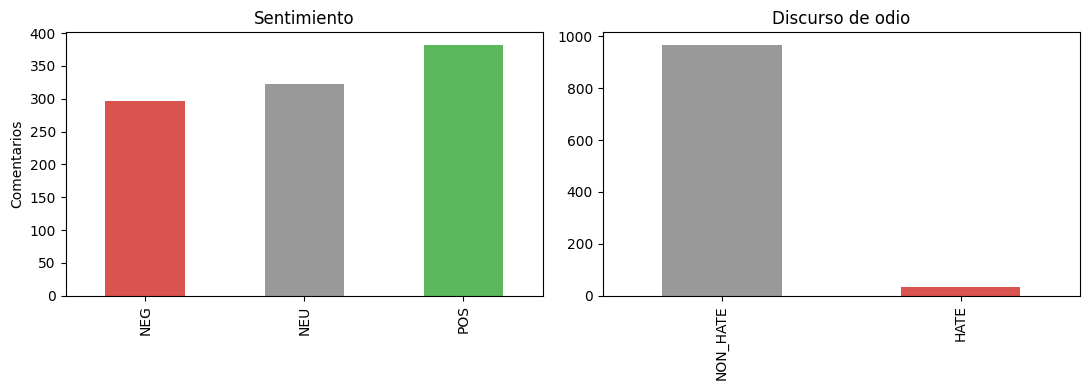

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

df["sentimiento"].value_counts().reindex(["NEG", "NEU", "POS"]).plot(
    kind="bar", color=["#d9534f", "#999999", "#5cb85c"], ax=ejes[0])
ejes[0].set_title("Sentimiento")
ejes[0].set_xlabel("")
ejes[0].set_ylabel("Comentarios")

df["odio"].value_counts().reindex(["NON_HATE", "HATE"]).plot(
    kind="bar", color=["#999999", "#d9534f"], ax=ejes[1])
ejes[1].set_title("Discurso de odio")
ejes[1].set_xlabel("")

plt.tight_layout()
plt.show()

In [34]:
# Porcentaje de cada sentimiento
(df["sentimiento"].value_counts(normalize=True) * 100).round(1)

,proportion
sentimiento,
POS,38.2
NEU,32.2
NEG,29.6


### 👍 Los comentarios con más apoyo

Los "Me gusta" indican qué opiniones encuentran eco en la comunidad. Vemos los diez comentarios con más likes y cómo los clasificaron los modelos.

In [35]:
df.sort_values("likes", ascending=False).head(10)[["comentario", "likes", "sentimiento", "odio"]]

,comentario,likes,sentimiento,odio
0,Hasta mi hermano Don sabe que en el rap hay un solo King Kong,224979,NEU,NON_HATE
18,"""esto es por los pibes... por el respeto que merece todo aquel que escribe""\nLa rompiste toda.",9602,POS,NON_HATE
24,"Vaya Temazo René y El Bizzarap\nLa mrd siempre sale a flote, gran frase",5758,POS,NON_HATE
76,Llegaron los duros 💪 temazo!,5717,POS,NON_HATE
16,100 millones 😎🔥,5100,NEG,NON_HATE
13,"""una cosa es ser artista, otra ser famoso"" ESTA PARTE SE GRITA",4972,NEU,NON_HATE
12,Todos viendo una tiradera por primera vez con 53 millones de vistas sin ser un hit para bailar y siendo 2 en tendencia mundial..... 2 minutos para un hit .. pero residente 8 minutos y si les tumbó el marketing residente... De un tirón... 💯🔥,4628,NEG,NON_HATE
25,Este no es home run es un GRAAAAAAND SLAAAAAAM,3833,POS,NON_HATE
26,La sesión de Daddy me trajo de vuelta acá🤭🫡,2977,NEU,NON_HATE
2,"Me acuerdo cuando residente cancelaron su concierto en Perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando",2482,NEG,NON_HATE


### 🔥 El odio que recibe apoyo

Los comentarios clasificados como odio con más "Me gusta" muestran qué formas de agresión logran resonancia. Conviene leerlos con atención: el modelo también se equivoca.

In [36]:
df[df["odio"] == "HATE"].sort_values("likes", ascending=False).head(10)[["comentario", "likes", "sentimiento", "odio_score"]]

,comentario,likes,sentimiento,odio_score
77,Es increíble que en 11 días tenga 64 millones una barbaridad que grande biza representante de Argentina,708,NEG,0.902
172,Que locura que ya hace tres años desde que salio esta tiradera magnifica de Rene. Increible como pasa el tiempo. Guao.,686,POS,0.661
216,"Uffff esta tremendo, RESIDENTE siendo RESIDENTE el puto amo ... todo un crack",386,POS,0.732
133,"Solo hablo de música, está es la mejor de bizzarap,este loco dejo la vara muy alta.",253,POS,0.656
137,UFFFFFFFFFFFFF SIN PALABRAAAAAAS! Increíble la lírica cruda y pura de Residente. Muy parado <3,207,NEG,0.574
75,Que hubiera sido un Bizza x Cancerbero,56,NEG,0.619
27,Alguien mas vino después de funar a Balvin? Residente yo SIEMPRE te creí,28,NEU,0.529
159,Residente siempre tuvo razón 🔥 tiró puros factos de balvin,7,NEU,0.777
367,Que nivel de barrida le dio a balvin,5,NEG,0.829
371,Residente 🫱‍🫲 Valentina,4,NEU,0.778


### 🔄 Sentimiento y odio

El odio no siempre coincide con el sentimiento negativo: también aparece en burlas o en comentarios irónicos. Una tabla cruzada muestra cómo se combinan las dos clasificaciones.

In [37]:
pd.crosstab(df["sentimiento"], df["odio"])

odio,HATE,NON_HATE
sentimiento,,
NEG,9,287
NEU,8,314
POS,16,366


### 🎯 ¿Qué se dice de J Balvin?

La canción es una respuesta a J Balvin, así que muchos comentarios hablan de él. Con `str.contains()` marcamos los comentarios que lo mencionan y comparamos su sentimiento con el del resto (`normalize="index"` muestra la proporción de cada fila).

In [38]:
df["menciona_balvin"] = df["comentario_limpio"].str.contains("balvin")

print("Comentarios que mencionan a Balvin:", df["menciona_balvin"].sum())

pd.crosstab(df["menciona_balvin"], df["sentimiento"], normalize="index").round(2)

Comentarios que mencionan a Balvin: 71


sentimiento,NEG,NEU,POS
menciona_balvin,,,
False,0.28,0.32,0.40
True,0.56,0.31,0.13


In [39]:
pd.crosstab(df["menciona_balvin"], df["odio"], normalize="index").round(2)

odio,HATE,NON_HATE
menciona_balvin,,
False,0.03,0.97
True,0.10,0.90


In [40]:
df[df["menciona_balvin"]].sort_values("likes", ascending=False).head(10)[["comentario", "likes", "sentimiento", "odio"]]

,comentario,likes,sentimiento,odio
129,"51.74 millones de vistas y siendo casi 9 minutos de canción!!! wooow ojalá tome un nuevo rumbo la música tras superar esta pandemia... yo diría; ""gracias Balvin"" por destapar la botella para que mi paladar saboree el elixir de la felicidad al darle en la jeta a tanto becerro con delirio de grandeza y cero destreza.",590,POS,NON_HATE
1,YO SOLO VOLVÍ AQUI PARA RECORDAR EL HATE DE JBALVIN AHORA QUE RECIÉN SE SEPARA DE VALENTINA,544,NEG,NON_HATE
102,Aquí después de Balvin?🤣🤣,426,NEU,NON_HATE
64,"ahora estendemos lo de J balvin relacionando a Diddy "" por cada mamada subía un escalon"" 👀",314,NEU,NON_HATE
205,Una bestialidad mi respeto residente. - R.I.P bobo balvin,235,NEG,NON_HATE
70,4:58 ahora ya sabemos por que \nJ Balvin no colaborará con el biza jajaxd,224,NEU,NON_HATE
254,"A noche cuando lo ví por primera vez tenía 2M de views, y ahora en menos de 24hs tiene 23M de views. Y hay gente que dice que René no pega temas jajaja. Que los escritores de J Balvin tomen nota como se hace.",216,NEU,NON_HATE
45,quien aqui despues de que anunciaron la session de j balvin,213,NEU,NON_HATE
130,"🤜🏼🤛🏽🔥🔥🔥🔥 J Balvin como otros artistas de acá de Colombia dieron la espalda en las marchas, personas que perdieron sus ojos, perdieron su vida, perdieron a hijos, herman@s, padres. Y nadie (Artistas) dijo NADA!!! 😞",201,NEG,NON_HATE
330,Madre mía q buena música me quedé sin palabras imagínate j Balvin pensé que iba a perder el tiempo pero me arrepiento de haber dicho eso por q es un temazo tengo el silbido en mi cabeza todavía buena música,185,POS,NON_HATE


### 🧬 Las expresiones más repetidas

Contamos los pares de palabras (*bigramas*) más frecuentes en los comentarios negativos, sin las palabras vacías del español (de, la, que...) ni los emojis, que suelen repetirse en cadena (🔥🔥🔥) y taparían a las palabras.

In [41]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer

nltk.download("stopwords", quiet=True)
stopwords_es = stopwords.words("spanish")

def sacar_emojis(texto):
    return re.sub(r":[^:\s]+:", " ", texto)   # los emojis convertidos a texto, como :fuego:

def expresiones_frecuentes(textos, n=15):
    vectorizador = CountVectorizer(stop_words=stopwords_es, ngram_range=(2, 2))
    matriz = vectorizador.fit_transform(textos.apply(sacar_emojis))
    tabla = pd.DataFrame({
        "expresion": vectorizador.get_feature_names_out(),
        "frecuencia": matriz.sum(axis=0).A1
    })
    return tabla.sort_values("frecuencia", ascending=False).head(n)

expresiones_frecuentes(df[df["sentimiento"] == "NEG"]["comentario_limpio"])

,expresion,frecuencia
1077,palabra lealtad,9
1557,tatuar palabra,8
830,lealtad olvida,7
1504,sigue muerto,4
1261,rapero favorito,4
1043,nunca mas,3
700,hacer sesión,3
690,hace años,3
1247,quieren ver,3
467,después ver,3


### ☁️ Nubes de palabras

Una nube de palabras muestra las palabras más frecuentes de un conjunto de textos: cuanto más grande, más veces aparece. Armamos una con los comentarios positivos y otra con los negativos, sin las palabras vacías del español y del inglés ni los emojis. Al comparar las dos nubes, conviene preguntarse si las palabras de la negativa expresan críticas o si vienen de frases de la canción que la gente cita.

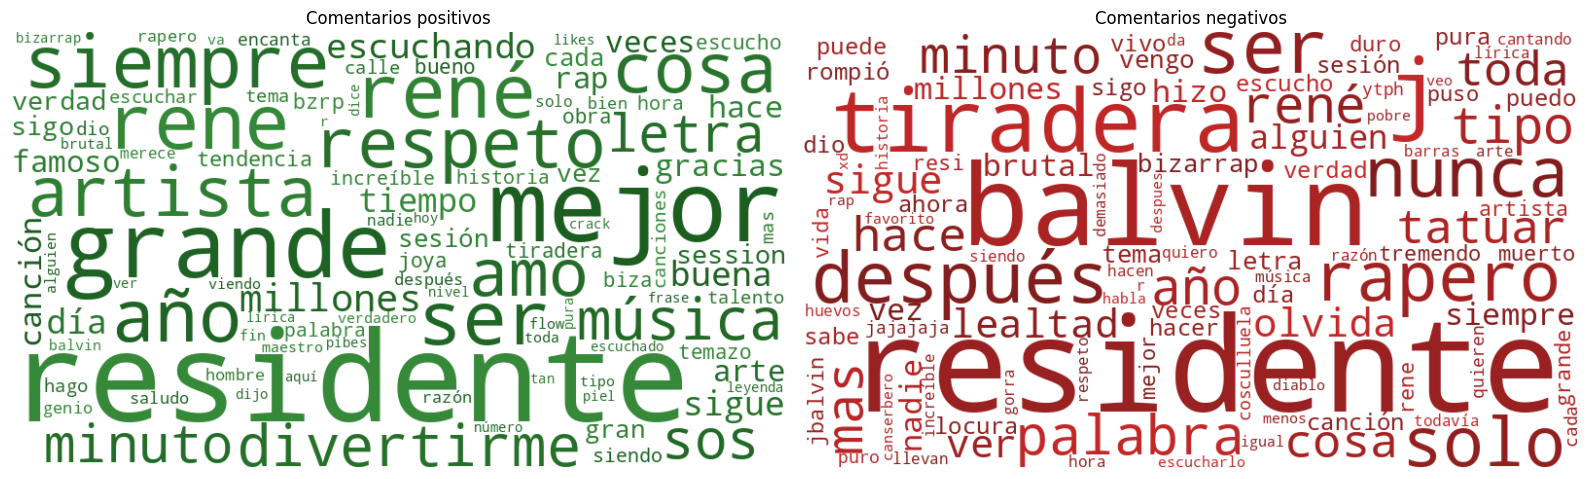

In [42]:
from wordcloud import WordCloud
from matplotlib.colors import LinearSegmentedColormap

palabras_vacias = set(stopwords_es) | set(stopwords.words("english")) | {"q", "si", "xq", "pa"}

verdes = LinearSegmentedColormap.from_list("verdes", ["#1b5e20", "#388e3c"])
rojos = LinearSegmentedColormap.from_list("rojos", ["#7f1d1d", "#c62828"])

def nube_de_palabras(sentimiento, colores):
    textos = df[df["sentimiento"] == sentimiento]["comentario_limpio"].apply(sacar_emojis)
    nube = WordCloud(width=800, height=450, background_color="white", colormap=colores,
                     stopwords=palabras_vacias, collocations=False, max_words=100)
    return nube.generate(" ".join(textos))

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))

ejes[0].imshow(nube_de_palabras("POS", verdes), interpolation="bilinear")
ejes[0].set_title("Comentarios positivos")
ejes[0].axis("off")

ejes[1].imshow(nube_de_palabras("NEG", rojos), interpolation="bilinear")
ejes[1].set_title("Comentarios negativos")
ejes[1].axis("off")

plt.tight_layout()
plt.show()

### 📅 ¿Cuándo se escribieron?

El video es de 2022, pero la gente sigue comentando. Contamos los comentarios por año.

In [43]:
df["fecha"].dt.year.value_counts().sort_index()

,count
fecha,
2022,276
2023,6
2024,6
2025,8
2026,704


## 💾 Guardar los resultados

Guardamos la tabla en Parquet, el formato por columnas de la Unidad 6: se puede abrir después con pandas, R o DuckDB sin volver a llamar a la API ni correr los modelos. El archivo aparece en el panel de archivos de Colab, desde donde se descarga.

In [44]:
df.to_parquet("comentarios_youtube.parquet", index=False)

pd.read_parquet("comentarios_youtube.parquet").shape

(1000, 11)

## 🔁 Otro video

Para analizar otro video, cambiar `VIDEO_ID` y volver a correr todo con **Entorno de ejecución > Ejecutar todas**.